# AI & ML in Data-Centric Engineering Workshop

This workbook is the worked solution for the pump telemetry exercise. It keeps the same structure as the participant notebook, but the code is filled in so you can see how each engineering choice changes the model.

The telemetry comes from an emulated high-pressure water injection pump. The data is intentionally messy in the same ways real field data is messy: dropout rows, slow pressure drift, noisy vibration, and a target efficiency signal that depends on the physics of cavitation and mechanical loading.

Before you start, make sure `pump_telemetry.csv` is available in this folder.

## Notebook Setup

These helper definitions keep the notebook readable. The point is to centralize the small pieces that will be reused later: loading the CSV safely, smoothing vibration, extracting rolling physical features, and enforcing simple safety bounds.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap
from scipy.signal import savgol_filter
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score
from sklearn.model_selection import train_test_split

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update(
    {
        "figure.figsize": (11, 6),
        "figure.dpi": 120,
        "axes.titlesize": 13,
        "axes.labelsize": 11,
        "axes.titleweight": "bold",
        "axes.grid": True,
        "grid.alpha": 0.25,
        "legend.frameon": False,
        "font.size": 10,
    }
)

csv_candidates = [
    Path("pump_telemetry.csv"),
    Path("..").resolve() / "pump_telemetry.csv",
    Path.cwd() / "pump_telemetry.csv",
]
for candidate in csv_candidates:
    if candidate.exists():
        csv_path = candidate
        break
else:
    raise FileNotFoundError("Could not find pump_telemetry.csv in the expected locations.")

telemetry_df = pd.read_csv(csv_path, parse_dates=["timestamp"])


def rolling_rms(signal: np.ndarray, window: int = 61) -> np.ndarray:
    series = pd.Series(signal, dtype="float64")
    return (
        series.rolling(window=window, min_periods=1, center=True)
        .apply(lambda values: float(np.sqrt(np.mean(np.square(values)))), raw=True)
        .bfill()
        .ffill()
        .to_numpy()
    )


def rolling_trend(signal: np.ndarray, window: int = 31) -> np.ndarray:
    values = np.asarray(signal, dtype=float)
    half_window = window // 2
    trend_values = []

    for index in range(values.shape[0]):
        start = max(0, index - half_window)
        stop = min(values.shape[0], index + half_window + 1)
        window_values = values[start:stop]
        if window_values.size < 2:
            trend_values.append(np.nan)
        else:
            trend_values.append((window_values[-1] - window_values[0]) / max(1, window_values.size - 1))

    return pd.Series(trend_values).bfill().ffill().to_numpy()


def enforce_physical_limits(predictions: np.ndarray, inputs: pd.DataFrame) -> np.ndarray:
    bounded = np.clip(np.asarray(predictions, dtype=float), 0.0, 1.0)
    cavitation_mask = inputs["pressure_reserve"].to_numpy() < -7.5
    return np.where(cavitation_mask, np.minimum(bounded, 0.2), bounded)


c:\Users\hp\OneDrive - University of Southampton\Year 3\2 DCE\DCE Code\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Part 1: The Dirty Reality

Physical telemetry is rarely clean. The emulator injects sparse dropouts, slow pressure drift, and high-frequency vibration noise, so the first job is to restore continuity without destroying the meaning of the signal.

Injected dropout rows: 76
                      timestamp  raw_vibration  cleaned_vibration  \
0 2026-01-01 00:00:00.000000000       0.083712           0.071794   
1 2026-01-01 00:01:00.000000001       0.023461           0.065028   
2 2026-01-01 00:01:59.999999998       0.104290           0.059821   
3 2026-01-01 00:03:00.000000000       0.113105           0.056172   
4 2026-01-01 00:04:00.000000001      -0.016758           0.054081   

   drifted_pressure  calibrated_pressure  
0        120.274766           120.274766  
1        119.946254           119.947087  
2        120.002127           120.003794  
3        120.017594           120.020094  
4        120.288416           120.291749  


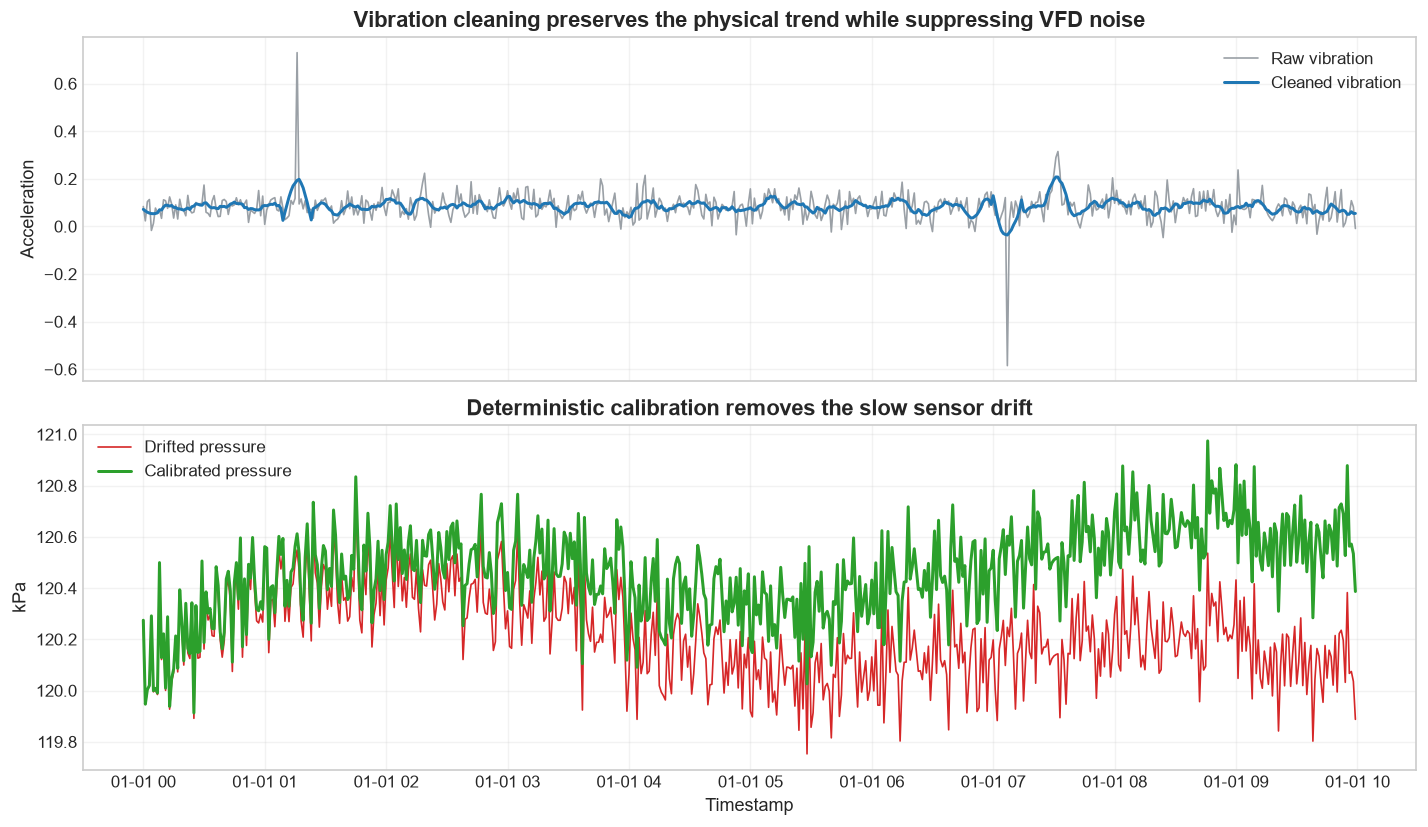

In [2]:
working_df = telemetry_df.copy()

dropout_count = int(working_df[["raw_vibration", "drifted_pressure", "motor_temp", "fluid_temp"]].isna().any(axis=1).sum())

working_df[["raw_vibration", "drifted_pressure", "motor_temp", "fluid_temp"]] = working_df[
    ["raw_vibration", "drifted_pressure", "motor_temp", "fluid_temp"]
].ffill()
working_df["cleaned_vibration"] = savgol_filter(working_df["raw_vibration"].to_numpy(), window_length=15, polyorder=2)

calibrated_pressure = []
for hour, pressure in zip(working_df["time_hours"].to_numpy(), working_df["drifted_pressure"].to_numpy()):
    calibrated_pressure.append(pressure + 0.05 * hour)
working_df["calibrated_pressure"] = calibrated_pressure

print(f"Injected dropout rows: {dropout_count}")
print(
    working_df[["timestamp", "raw_vibration", "cleaned_vibration", "drifted_pressure", "calibrated_pressure"]].head()
)

preview = working_df.iloc[:600].copy()
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
axes[0].plot(preview["timestamp"], preview["raw_vibration"], color="#9aa0a6", linewidth=1, label="Raw vibration")
axes[0].plot(preview["timestamp"], preview["cleaned_vibration"], color="#1f77b4", linewidth=1.8, label="Cleaned vibration")
axes[0].set_title("Vibration cleaning preserves the physical trend while suppressing VFD noise")
axes[0].set_ylabel("Acceleration")
axes[0].legend()

axes[1].plot(preview["timestamp"], preview["drifted_pressure"], color="#d62728", linewidth=1, label="Drifted pressure")
axes[1].plot(preview["timestamp"], preview["calibrated_pressure"], color="#2ca02c", linewidth=1.8, label="Calibrated pressure")
axes[1].set_title("Deterministic calibration removes the slow sensor drift")
axes[1].set_ylabel("kPa")
axes[1].set_xlabel("Timestamp")
axes[1].legend()
plt.tight_layout()
plt.show()

## Part 2: Feature Engineering

A naive model sees only one row at a time. A data-centric model uses short histories and physics-aware features, so the same algorithm can recover more of the real signal hidden inside the telemetry.

Naive raw-feature R^2: 0.988
Engineered physics-feature R^2: 0.990
Improvement: 0.002


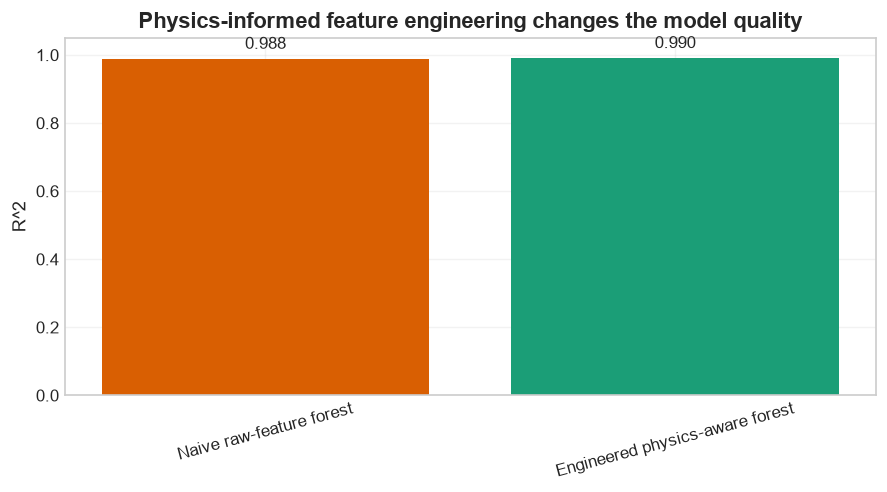

In [3]:
raw_features = ["raw_vibration", "drifted_pressure", "motor_temp"]
engineered_features = ["vibration_rms", "vibration_trend", "pressure_reserve", "motor_temp"]

vibration_rms = rolling_rms(working_df["cleaned_vibration"].to_numpy(), window=61)
vibration_trend = rolling_trend(working_df["cleaned_vibration"].to_numpy(), window=31)
pressure_reserve_feature = (
    working_df["calibrated_pressure"].to_numpy()
    - pd.Series(working_df["calibrated_pressure"]).rolling(window=91, min_periods=1, center=True).mean().bfill().ffill().to_numpy()
 )

feature_array = np.column_stack(
    [
        working_df["raw_vibration"].to_numpy(),
        working_df["drifted_pressure"].to_numpy(),
        working_df["motor_temp"].to_numpy(),
        vibration_rms,
        vibration_trend,
        pressure_reserve_feature,
        working_df["pump_efficiency"].to_numpy(),
    ]
)

feature_df = pd.DataFrame(
    feature_array,
    columns=[
        "raw_vibration",
        "drifted_pressure",
        "motor_temp",
        "vibration_rms",
        "vibration_trend",
        "pressure_reserve",
        "pump_efficiency",
    ],
)

train_df, test_df = train_test_split(feature_df, test_size=0.3, random_state=42, shuffle=True)

baseline_model = RandomForestRegressor(n_estimators=80, random_state=42, n_jobs=-1)
baseline_model.fit(train_df[raw_features], train_df["pump_efficiency"])
baseline_predictions = baseline_model.predict(test_df[raw_features])
baseline_r2 = r2_score(test_df["pump_efficiency"], baseline_predictions)

engineered_model = RandomForestRegressor(n_estimators=120, random_state=42, n_jobs=-1)
engineered_model.fit(train_df[engineered_features], train_df["pump_efficiency"])
engineered_predictions = engineered_model.predict(test_df[engineered_features])
engineered_r2 = r2_score(test_df["pump_efficiency"], engineered_predictions)

print(f"Naive raw-feature R^2: {baseline_r2:.3f}")
print(f"Engineered physics-feature R^2: {engineered_r2:.3f}")
print(f"Improvement: {engineered_r2 - baseline_r2:.3f}")

comparison = pd.DataFrame(
    {
        "model": ["Naive raw-feature forest", "Engineered physics-aware forest"],
        "r2": [baseline_r2, engineered_r2],
    }
)
fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.bar(comparison["model"], comparison["r2"], color=["#d95f02", "#1b9e77"])
ax.set_ylim(0, 1.05)
ax.set_ylabel("R^2")
ax.set_title("Physics-informed feature engineering changes the model quality")
ax.tick_params(axis="x", rotation=15)
for idx, value in enumerate(comparison["r2"]):
    ax.text(idx, value + 0.02, f"{value:.3f}", ha="center", va="bottom", fontsize=10)
plt.tight_layout()
plt.show()


## Part 3: Boundary Concepts and Uncertainty

When the pump leaves the operating range seen during training, the prediction alone is not enough. We also need an uncertainty signal, because a model that is confident outside its experience can be more dangerous than one that admits it is unsure.

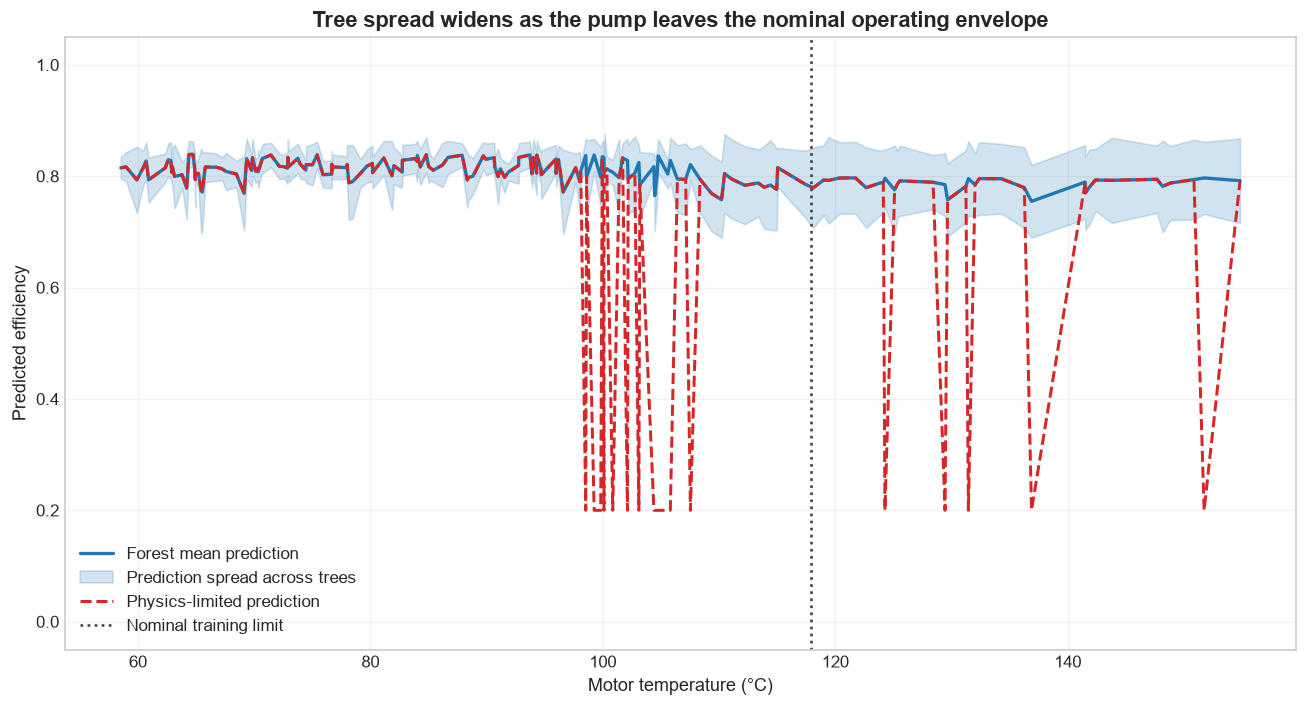

OOD mean prediction range: 0.755 to 0.839
OOD uncertainty range: 0.010 to 0.055
Physics-limited tail values: [0.78177878 0.78773922 0.79392164 0.2        0.79194069]


In [4]:
nominal_mask = (train_df["motor_temp"] < 68.0) & (train_df["pressure_reserve"] > -4.0)
nominal_pool = train_df.loc[nominal_mask, engineered_features + ["pump_efficiency"]].dropna().copy()
nominal_sample = nominal_pool.sample(n=min(650, len(nominal_pool)), random_state=42).sort_index()

X_nominal = nominal_sample[engineered_features].copy()
y_nominal = nominal_sample["pump_efficiency"].to_numpy()

gpr_model = RandomForestRegressor(n_estimators=120, random_state=42, n_jobs=-1)
gpr_model.fit(X_nominal.to_numpy(), y_nominal)

ood_slice = test_df.iloc[:180].copy()
tail_mask = np.zeros(len(ood_slice), dtype=bool)
tail_mask[-18:] = True
ood_slice = ood_slice.assign(
    motor_temp=ood_slice["motor_temp"].astype(float).to_numpy() + np.linspace(0.0, 45.0, len(ood_slice)),
    pressure_reserve=np.where(tail_mask, -8.0, ood_slice["pressure_reserve"].to_numpy()),
)

ood_matrix = ood_slice[engineered_features].to_numpy()
ood_trees = np.stack([tree.predict(ood_matrix) for tree in gpr_model.estimators_], axis=0)
ood_mean = ood_trees.mean(axis=0)
ood_std = ood_trees.std(axis=0)
validated_mean = enforce_physical_limits(ood_mean, ood_slice)

x_axis = ood_slice["motor_temp"].to_numpy()
order = np.argsort(x_axis)
x_sorted = x_axis[order]
mean_sorted = ood_mean[order]
std_sorted = ood_std[order]
validated_sorted = validated_mean[order]

fig, ax = plt.subplots(figsize=(11, 6))
ax.plot(x_sorted, mean_sorted, color="#1f77b4", linewidth=2, label="Forest mean prediction")
ax.fill_between(
    x_sorted,
    mean_sorted - 1.5 * std_sorted,
    mean_sorted + 1.5 * std_sorted,
    color="#1f77b4",
    alpha=0.2,
    label="Prediction spread across trees",
)
ax.plot(x_sorted, validated_sorted, color="#d62728", linewidth=1.8, linestyle="--", label="Physics-limited prediction")
nominal_max = train_df["motor_temp"].max()
ax.axvline(nominal_max, color="#444444", linestyle=":", linewidth=1.6, label="Nominal training limit")
ax.set_xlabel("Motor temperature (°C)")
ax.set_ylabel("Predicted efficiency")
ax.set_title("Tree spread widens as the pump leaves the nominal operating envelope")
ax.set_ylim(-0.05, 1.05)
ax.legend(loc="lower left")
plt.tight_layout()
plt.show()

print(f"OOD mean prediction range: {ood_mean.min():.3f} to {ood_mean.max():.3f}")
print(f"OOD uncertainty range: {ood_std.min():.3f} to {ood_std.max():.3f}")
print(f"Physics-limited tail values: {validated_sorted[-5:]}")


## Part 4: Ethics and Forensic Audit

Explainability is not decorative. In a safety-critical asset, feature attributions are part of the audit trail. SHAP helps show which sensor channel is responsible for a shutdown-level prediction instead of leaving the explanation buried inside a black box.

Mean absolute SHAP importance:
motor_temp          0.150325
vibration_rms       0.008449
pressure_reserve    0.003499
vibration_trend     0.001198
dtype: float64
Dominant sensor channel: motor_temp


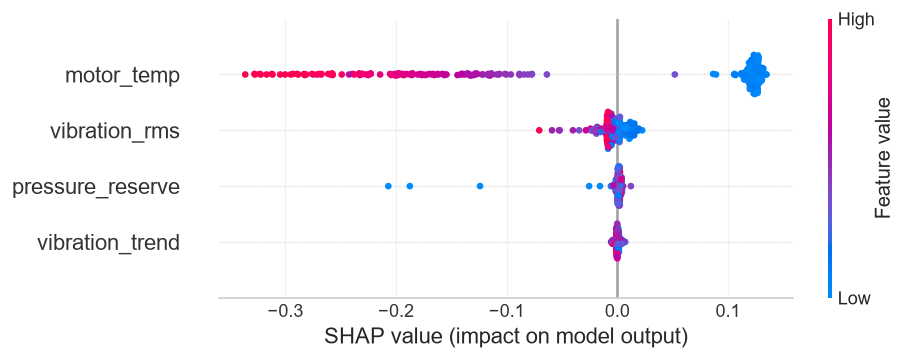

Most anomalous telemetry frame index within SHAP sample: 261


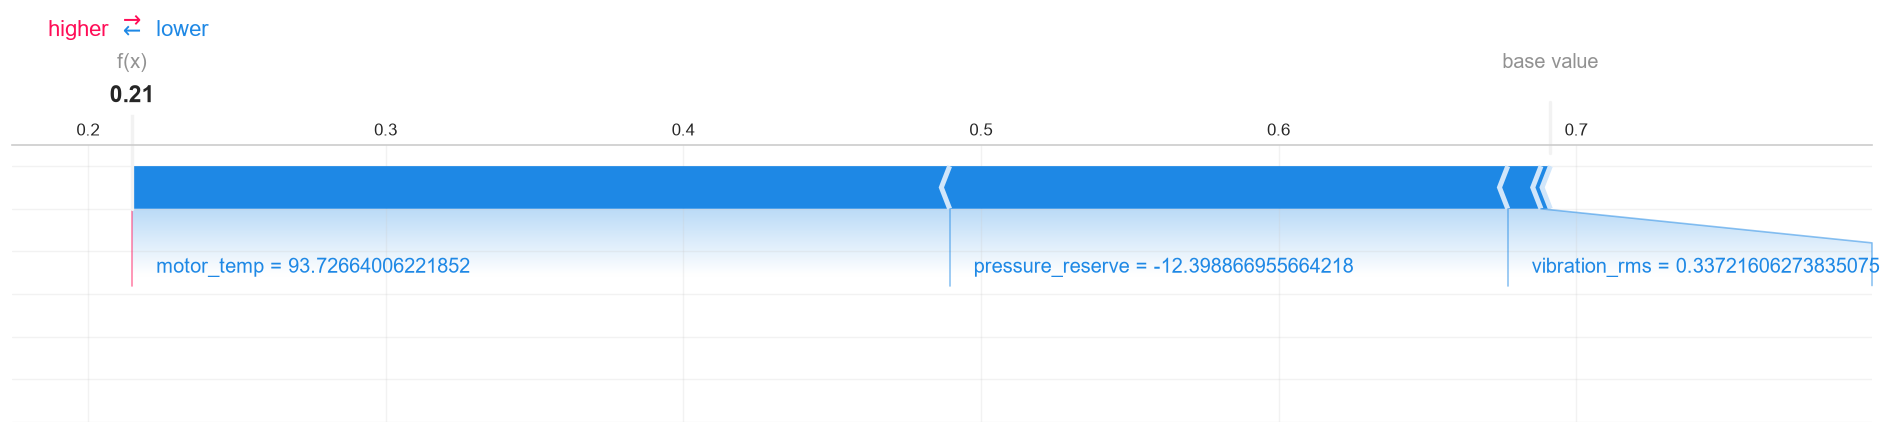

In [5]:
shap.initjs()
shap_sample = test_df.sample(n=min(300, len(test_df)), random_state=42).copy()
X_shap = shap_sample[engineered_features]
shap_explainer = shap.TreeExplainer(engineered_model)
shap_values = shap_explainer.shap_values(X_shap)

feature_importance = pd.Series(np.abs(shap_values).mean(axis=0), index=engineered_features).sort_values(ascending=False)
dominant_feature = feature_importance.index[0]
print("Mean absolute SHAP importance:")
print(feature_importance)
print(f"Dominant sensor channel: {dominant_feature}")

shap.summary_plot(shap_values, X_shap, show=True)

top_row = int(np.argmin(engineered_model.predict(X_shap)))
expected_value = float(np.asarray(shap_explainer.expected_value).squeeze())
print(f"Most anomalous telemetry frame index within SHAP sample: {top_row}")
shap.force_plot(
    expected_value,
    shap_values[top_row],
    X_shap.iloc[top_row],
    matplotlib=True,
    show=True,
)


## Wrap-Up

If the notebook is working, the raw features should look weak, the engineered features should recover the physical signal, the uncertainty band should widen in the extrapolation zone, and SHAP should point to a specific sensor channel rather than a vague story.